In [9]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

In [10]:
#load processed data
X_train = pd.read_csv("../Preprocessing/X_train_processed.csv")
X_test = pd.read_csv("../Preprocessing/X_test_processed.csv")

y_train = pd.read_csv("../Preprocessing/y_train_processed.csv").squeeze()
y_test = pd.read_csv("../Preprocessing/y_test_processed.csv").squeeze()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (36168, 64)
X_test: (9043, 64)
y_train: (36168,)
y_test: (9043,)


In [11]:
#check and convert target
print("Training target values:")
print(y_train.value_counts())

print("\nTesting target values:")
print(y_test.value_counts())

y_train = y_train.map({"no": 0, "yes": 1})
y_test = y_test.map({"no": 0, "yes": 1})

print("\nConverted target:")
print(y_train.value_counts())

Training target values:
y
no     31937
yes     4231
Name: count, dtype: int64

Testing target values:
y
no     7985
yes    1058
Name: count, dtype: int64

Converted target:
y
0    31937
1     4231
Name: count, dtype: int64


In [12]:
#check for missing values
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0


In [13]:
#Create random forest model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print(model)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)


In [14]:
#train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [15]:
#generate predictions
y_pred = model.predict(X_test)

y_pred_proba = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [16]:
#Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

Accuracy: 0.8966


In [17]:
#Precision,recall and f1 score
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Precision: 0.5523
Recall: 0.6134
F1-score: 0.5813


In [18]:
#ROC-AUC
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.9266


In [19]:
#Classification report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No", "Yes"]
    )
)

              precision    recall  f1-score   support

          No       0.95      0.93      0.94      7985
         Yes       0.55      0.61      0.58      1058

    accuracy                           0.90      9043
   macro avg       0.75      0.77      0.76      9043
weighted avg       0.90      0.90      0.90      9043



In [20]:
#confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[7459  526]
 [ 409  649]]


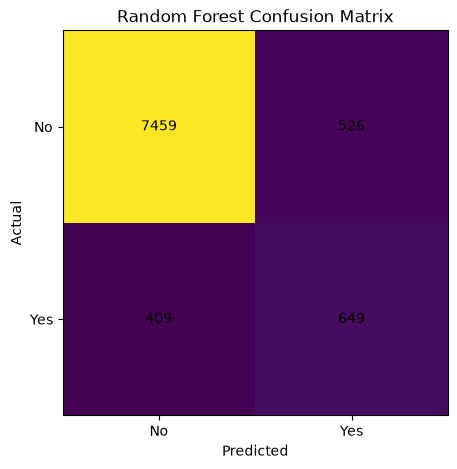

In [21]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

In [22]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
3,numerical__duration,0.320885
8,numerical__balance_to_age,0.057227
1,numerical__balance,0.056212
2,numerical__day,0.053463
0,numerical__age,0.053266
38,categorical__contact_unknown,0.024694
53,categorical__poutcome_success,0.024183
5,numerical__pdays,0.023559
10,numerical__previous_positive_outcome,0.022386
4,numerical__campaign,0.020249


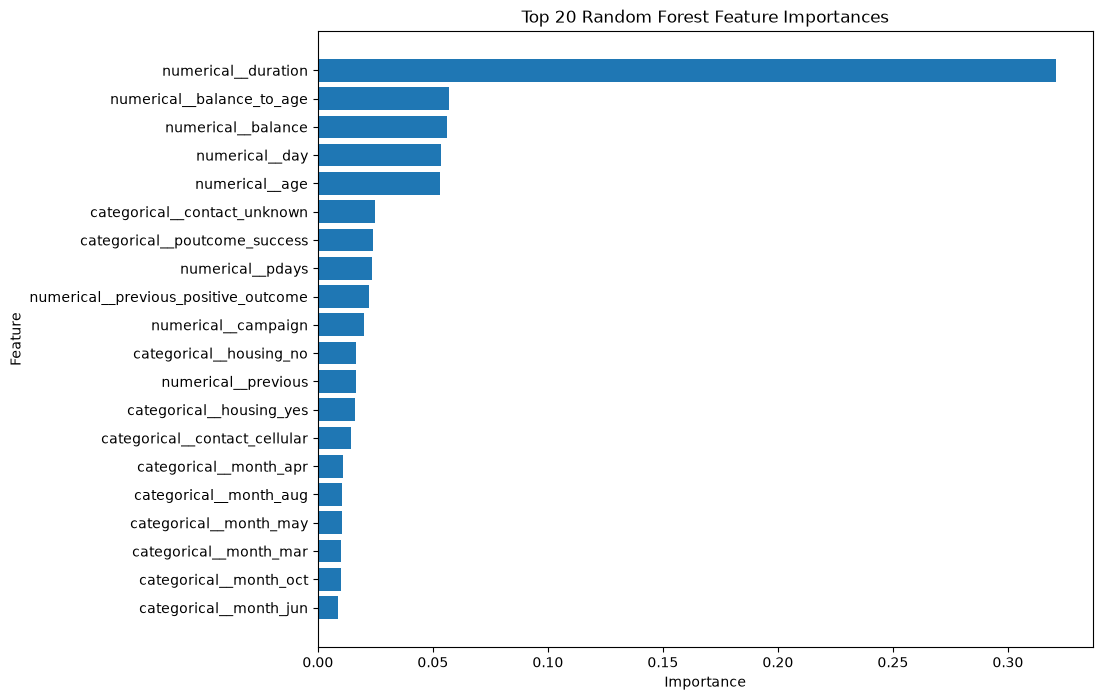

In [23]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Feature Importances")

plt.gca().invert_yaxis()

plt.show()

In [24]:
#Store results
model2_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Random Forest": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

model2_results

,Metric,Random Forest
0,Accuracy,0.896605
1,Precision,0.552340
2,Recall,0.613422
3,F1-score,0.581281
4,ROC-AUC,0.926581


In [25]:
model2_results.to_csv(
    "model2_results.csv",
    index=False
)

feature_importance.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

print("Model 2 results saved successfully.")

Model 2 results saved successfully.


In [26]:
# Save Random Forest predictions for statistical comparison

model2_predictions = pd.DataFrame({
    "actual": y_test,
    "model2_prediction": y_pred
})

model2_predictions.to_csv(
    "model2_predictions.csv",
    index=False
)

print("Model 2 predictions saved successfully.")

Model 2 predictions saved successfully.


In [27]:
model2_predictions = pd.DataFrame({
    "actual": y_test,
    "model2_prediction": y_pred
})

model2_predictions.to_csv(
    "model2_predictions.csv",
    index=False
)

print("Model 2 predictions saved.")

Model 2 predictions saved.
